# Same Winds, Different Fires
### How the Palisades and Eaton Fires Spread Under One Santa Ana Event

GOES-18 (GOES-West) exploratory analysis for the DSC 106 Project 3 checkpoint. All data is read directly from NOAA's public AWS bucket, so no account or downloads are needed.

**Time window:** Tuesday Jan 7, 2025, 8:00 AM PST to Thursday Jan 9, 8:00 AM PST.

**GOES-18 products used**
- `ABI-L2-FDCC` Fire Detection: every 5 minutes at about 2 km resolution. Gives each fire pixel's radiative power (MW), temperature, and area.
- `ABI-L2-DMWC` and `ABI-L2-DMWVC` Derived Motion Winds: wind speed and direction estimated by tracking clouds (band 14) and water vapor (band 8) between images.
- `ABI-L2-CMIPC` band 7 (3.9 µm): a heat-signature image for one moment when both fires were burning.

**Note on the wind data:** these winds come from tracking features in the atmosphere, so many vectors sit above the ground. Santa Ana winds are strongest near the surface under clear skies, where the satellite has little to track. The wind cells print the height range (as pressure) so the limitation is visible.

**To run:** Runtime → Run all. Expect roughly 10 to 20 minutes, mostly downloading the 576 fire scans.

In [1]:
!pip install -q s3fs h5netcdf

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.


## Setup

In [2]:
import re
import os
import json
import zipfile
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import s3fs

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

BUCKET = "noaa-goes18"
START = pd.Timestamp("2025-01-07 16:00", tz="UTC")
END = pd.Timestamp("2025-01-09 16:00", tz="UTC")
LOCAL_TIMEZONE = "America/Los_Angeles"

LA_REGION = {"west": -118.95, "east": -117.85, "south": 33.85, "north": 34.45}
WIND_REGION = {"west": -120.5, "east": -116.5, "south": 33.0, "north": 35.5}

FIRES = {
    "Palisades": {
        "ignition": pd.Timestamp("2025-01-07 18:30", tz="UTC"),
        "lat": 34.0725,
        "lon": -118.5425,
        "box": {"west": -118.80, "east": -118.45, "south": 33.98, "north": 34.15},
    },
    "Eaton": {
        "ignition": pd.Timestamp("2025-01-08 02:18", tz="UTC"),
        "lat": 34.1900,
        "lon": -118.1050,
        "box": {"west": -118.22, "east": -117.98, "south": 34.13, "north": 34.30},
    },
}
FIRE_NAMES = list(FIRES.keys())
FIRE_COLORS = {"Palisades": "#e8743b", "Eaton": "#3b6fd8", "Other": "#9a9a9a"}
WIND_COLOR = "#2a9d8f"

FIRE_CODES = [10, 11, 12, 13, 14, 30, 31, 32, 33, 34]
WIND_PRODUCTS = [("ABI-L2-DMWC", "C14"), ("ABI-L2-DMWVC", "C08")]

IGNITION_TIMES = {}
ORIGIN_LATITUDES = {}
ORIGIN_LONGITUDES = {}
for fire_name in FIRE_NAMES:
    IGNITION_TIMES[fire_name] = FIRES[fire_name]["ignition"]
    ORIGIN_LATITUDES[fire_name] = FIRES[fire_name]["lat"]
    ORIGIN_LONGITUDES[fire_name] = FIRES[fire_name]["lon"]

## Helper functions

In [3]:
fs = s3fs.S3FileSystem(anon=True)


def scan_time_from_path(path):
    match = re.search(r"_s(\d{4})(\d{3})(\d{2})(\d{2})(\d{2})", path)
    year, day_of_year, hour, minute, second = match.groups()
    start_of_year = pd.Timestamp(year=int(year), month=1, day=1, tz="UTC")
    return start_of_year + pd.Timedelta(days=int(day_of_year) - 1, hours=int(hour), minutes=int(minute), seconds=int(second))


def list_files(product, start, end, band=""):
    paths = []
    for hour in pd.date_range(start.floor("h"), end, freq="h"):
        folder = f"{BUCKET}/{product}/{hour.year}/{str(hour.dayofyear).zfill(3)}/{str(hour.hour).zfill(2)}"
        try:
            hour_paths = fs.ls(folder)
        except FileNotFoundError:
            hour_paths = []
        for path in hour_paths:
            if path.endswith(".nc") and band in path:
                paths.append(path)
    files = pd.DataFrame({"path": paths})
    files["time"] = pd.to_datetime(files["path"].map(scan_time_from_path), utc=True)
    in_window = (files["time"] >= start) & (files["time"] < end)
    return files[in_window].sort_values("time").reset_index(drop=True)


def compute_lat_lon(scan):
    projection = scan["goes_imager_projection"]
    equatorial_radius = projection.attrs["semi_major_axis"]
    polar_radius = projection.attrs["semi_minor_axis"]
    satellite_distance = projection.attrs["perspective_point_height"] + equatorial_radius
    origin_longitude = np.radians(projection.attrs["longitude_of_projection_origin"])
    x_radians, y_radians = np.meshgrid(scan["x"].values, scan["y"].values)
    radius_ratio = equatorial_radius ** 2 / polar_radius ** 2

    coefficient_a = np.sin(x_radians) ** 2 + np.cos(x_radians) ** 2 * (np.cos(y_radians) ** 2 + radius_ratio * np.sin(y_radians) ** 2)
    coefficient_b = -2 * satellite_distance * np.cos(x_radians) * np.cos(y_radians)
    coefficient_c = satellite_distance ** 2 - equatorial_radius ** 2

    with np.errstate(invalid="ignore"):
        distance_to_point = (-coefficient_b - np.sqrt(coefficient_b ** 2 - 4 * coefficient_a * coefficient_c)) / (2 * coefficient_a)
        point_x = distance_to_point * np.cos(x_radians) * np.cos(y_radians)
        point_y = -distance_to_point * np.sin(x_radians)
        point_z = distance_to_point * np.cos(x_radians) * np.sin(y_radians)
        latitude = np.degrees(np.arctan(radius_ratio * point_z / np.sqrt((satellite_distance - point_x) ** 2 + point_y ** 2)))
        longitude = np.degrees(origin_longitude - np.arctan(point_y / (satellite_distance - point_x)))
    return latitude, longitude


def find_region_window(path, region):
    with fs.open(path) as remote_file:
        scan = xr.open_dataset(remote_file, engine="h5netcdf")
        latitude, longitude = compute_lat_lon(scan)
    with np.errstate(invalid="ignore"):
        inside = (longitude >= region["west"]) & (longitude <= region["east"]) & (latitude >= region["south"]) & (latitude <= region["north"])
    row_indexes = np.where(inside.any(axis=1))[0]
    column_indexes = np.where(inside.any(axis=0))[0]
    row_slice = slice(row_indexes.min(), row_indexes.max() + 1)
    column_slice = slice(column_indexes.min(), column_indexes.max() + 1)
    return row_slice, column_slice, latitude[row_slice, column_slice], longitude[row_slice, column_slice]


def label_fire(latitude, longitude):
    for fire_name in FIRE_NAMES:
        box = FIRES[fire_name]["box"]
        inside_longitude = box["west"] <= longitude <= box["east"]
        inside_latitude = box["south"] <= latitude <= box["north"]
        if inside_longitude and inside_latitude:
            return fire_name
    return "Other"


def distance_km(latitude_1, longitude_1, latitude_2, longitude_2):
    phi_1 = np.radians(latitude_1)
    phi_2 = np.radians(latitude_2)
    half_chord = np.sin((phi_2 - phi_1) / 2) ** 2 + np.cos(phi_1) * np.cos(phi_2) * np.sin(np.radians(longitude_2 - longitude_1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(half_chord))


def mean_direction(degrees, weights):
    radians = np.radians(degrees)
    east_total = (np.sin(radians) * weights).sum()
    north_total = (np.cos(radians) * weights).sum()
    return (np.degrees(np.arctan2(east_total, north_total)) + 360) % 360


def compass_name(degrees):
    names = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
    return names[int(((degrees + 22.5) % 360) // 45)]

## Load fire detections (`ABI-L2-FDCC`)

For each 5-minute scan, keep only pixels over the Los Angeles basin whose fire mask means "fire" (codes 10 to 14 and their temporally filtered versions 30 to 34; low-probability codes 15 and 35 are left out as noisy). Each pixel is labeled Palisades, Eaton, or Other using a box around each fire. Detections inside a fire's box from more than 30 minutes before that fire's reported ignition are dropped.

In [4]:
fire_files = list_files("ABI-L2-FDCC", START, END)
print(len(fire_files), "fire scans from", fire_files["time"].min(), "to", fire_files["time"].max())

FIRE_ROWS, FIRE_COLUMNS, FIRE_LATITUDE, FIRE_LONGITUDE = find_region_window(fire_files["path"][0], LA_REGION)
print("Los Angeles window:", FIRE_LATITUDE.shape, "pixels")

detection_tables = []
good_scan_times = []
for index, scan_row in fire_files.iterrows():
    try:
        with fs.open(scan_row["path"]) as remote_file:
            scan = xr.open_dataset(remote_file, engine="h5netcdf")
            window = scan[["Mask", "Power", "Temp", "Area"]].isel(y=FIRE_ROWS, x=FIRE_COLUMNS).load()
    except Exception as error:
        print("skipped", scan_row["path"], error)
        continue
    good_scan_times.append(scan_row["time"])
    mask_values = window["Mask"].values
    fire_y, fire_x = np.where(np.isin(mask_values, FIRE_CODES))
    scan_table = pd.DataFrame({
        "pixel_y": fire_y + FIRE_ROWS.start,
        "pixel_x": fire_x + FIRE_COLUMNS.start,
        "lat": FIRE_LATITUDE[fire_y, fire_x],
        "lon": FIRE_LONGITUDE[fire_y, fire_x],
        "mask": mask_values[fire_y, fire_x].astype(int),
        "frp": window["Power"].values[fire_y, fire_x],
        "temp": window["Temp"].values[fire_y, fire_x],
        "area": window["Area"].values[fire_y, fire_x],
    })
    scan_table["time"] = scan_row["time"]
    detection_tables.append(scan_table)
    if index % 50 == 0:
        print(index, "of", len(fire_files), "scans read")

print("finished reading", len(good_scan_times), "scans")

576 fire scans from 2025-01-07 16:01:17+00:00 to 2025-01-09 15:56:17+00:00
Los Angeles window: (26, 51) pixels
0 of 576 scans read
50 of 576 scans read
100 of 576 scans read
150 of 576 scans read
200 of 576 scans read
250 of 576 scans read
300 of 576 scans read
350 of 576 scans read
400 of 576 scans read
450 of 576 scans read
500 of 576 scans read
550 of 576 scans read
finished reading 576 scans


In [5]:
detections = pd.concat(detection_tables, ignore_index=True)
detections["time"] = pd.to_datetime(detections["time"], utc=True)

fire_labels = []
for latitude_value, longitude_value in zip(detections["lat"], detections["lon"]):
    fire_labels.append(label_fire(latitude_value, longitude_value))
detections["fire"] = fire_labels

detections["time_local"] = detections["time"].dt.tz_convert(LOCAL_TIMEZONE)
detection_ignitions = pd.to_datetime(detections["fire"].map(IGNITION_TIMES), utc=True)
detections["hours_since_ignition"] = (detections["time"] - detection_ignitions).dt.total_seconds() / 3600
before_ignition = detections["hours_since_ignition"] < -0.5
detections = detections[before_ignition == False].reset_index(drop=True)

print(len(detections), "fire-pixel detections")
detections.groupby("fire").agg(detections=("frp", "size"), peak_pixel_frp_mw=("frp", "max")).round(1)

7931 fire-pixel detections


,detections,peak_pixel_frp_mw
fire,,
Eaton,2413,2666.800049
Other,212,1164.699951
Palisades,5306,2681.600098


### Per-scan totals for each fire

In [6]:
all_scan_times = pd.DatetimeIndex(good_scan_times)
timeseries_tables = []
for fire_name in FIRE_NAMES:
    fire_detections = detections[detections["fire"] == fire_name]
    per_scan = fire_detections.groupby("time").agg(frp_total=("frp", "sum"), pixel_count=("frp", "size"))
    per_scan = per_scan.reindex(all_scan_times, fill_value=0)
    per_scan.index.name = "time"
    per_scan = per_scan.reset_index()
    per_scan["fire"] = fire_name
    per_scan["frp_smooth"] = per_scan["frp_total"].rolling(6, min_periods=1, center=True).mean()
    per_scan["pixels_smooth"] = per_scan["pixel_count"].rolling(6, min_periods=1, center=True).mean()
    timeseries_tables.append(per_scan)

timeseries = pd.concat(timeseries_tables, ignore_index=True)
timeseries["time_local"] = timeseries["time"].dt.tz_convert(LOCAL_TIMEZONE)
timeseries["hour"] = timeseries["time"].dt.floor("h")
timeseries.head()

,time,frp_total,pixel_count,fire,frp_smooth,pixels_smooth,time_local,hour
0,2025-01-07 16:01:17+00:00,0.0,0,Palisades,0.0,0.0,2025-01-07 08:01:17-08:00,2025-01-07 16:00:00+00:00
1,2025-01-07 16:06:17+00:00,0.0,0,Palisades,0.0,0.0,2025-01-07 08:06:17-08:00,2025-01-07 16:00:00+00:00
2,2025-01-07 16:11:17+00:00,0.0,0,Palisades,0.0,0.0,2025-01-07 08:11:17-08:00,2025-01-07 16:00:00+00:00
3,2025-01-07 16:16:17+00:00,0.0,0,Palisades,0.0,0.0,2025-01-07 08:16:17-08:00,2025-01-07 16:00:00+00:00
4,2025-01-07 16:21:17+00:00,0.0,0,Palisades,0.0,0.0,2025-01-07 08:21:17-08:00,2025-01-07 16:00:00+00:00


## Load satellite-derived winds (`ABI-L2-DMWC` and `ABI-L2-DMWVC`)

One file per hour from each wind product, keeping vectors over Southern California. Wind direction is reported as the direction the wind blows **from** (a Santa Ana wind comes from the northeast, about 45°). The cell also computes the direction it blows **toward**, so it can be compared with the direction the fires spread.

In [7]:
wind_tables = []
for product, band in WIND_PRODUCTS:
    wind_files = list_files(product, START, END, band)
    print(product, band, len(wind_files), "files found")
    if len(wind_files) == 0:
        continue
    wind_files["hour"] = wind_files["time"].dt.floor("h")
    hourly_wind_files = wind_files.drop_duplicates("hour")
    for index, file_row in hourly_wind_files.iterrows():
        try:
            with fs.open(file_row["path"]) as remote_file:
                wind_scan = xr.open_dataset(remote_file, engine="h5netcdf")
                wind_table = pd.DataFrame({
                    "lat": wind_scan["lat"].values,
                    "lon": wind_scan["lon"].values,
                    "speed_ms": wind_scan["wind_speed"].values,
                    "direction_from_deg": wind_scan["wind_direction"].values,
                    "pressure_hpa": wind_scan["pressure"].values,
                })
        except Exception as error:
            print("skipped", file_row["path"], error)
            continue
        inside = (wind_table["lon"] >= WIND_REGION["west"]) & (wind_table["lon"] <= WIND_REGION["east"]) & (wind_table["lat"] >= WIND_REGION["south"]) & (wind_table["lat"] <= WIND_REGION["north"])
        wind_table = wind_table[inside].copy()
        wind_table["time"] = file_row["time"]
        wind_table["source"] = f"{product} {band}"
        wind_tables.append(wind_table)

if len(wind_tables) > 0:
    winds = pd.concat(wind_tables, ignore_index=True)
    winds = winds.dropna(subset=["speed_ms", "direction_from_deg"])
else:
    winds = pd.DataFrame(columns=["lat", "lon", "speed_ms", "direction_from_deg", "pressure_hpa", "time", "source"])

winds["time"] = pd.to_datetime(winds["time"], utc=True)
winds["time_local"] = winds["time"].dt.tz_convert(LOCAL_TIMEZONE)
winds["hour"] = winds["time"].dt.floor("h")
winds["direction_to_deg"] = (winds["direction_from_deg"].astype(float) + 180) % 360
wind_from_radians = np.radians(winds["direction_from_deg"].astype(float))
winds["wind_east"] = -winds["speed_ms"].astype(float) * np.sin(wind_from_radians)
winds["wind_north"] = -winds["speed_ms"].astype(float) * np.cos(wind_from_radians)

print(len(winds), "wind vectors over Southern California")
if len(winds) > 0:
    print(winds.groupby("source").size())
    print("Pressure range (hPa):", winds["pressure_hpa"].min(), "to", winds["pressure_hpa"].max())
    print("Vectors in the lower atmosphere (pressure of 700 hPa or more):", (winds["pressure_hpa"] >= 700).sum())

if len(winds) > 0:
    hourly_wind = winds.groupby("hour").agg(median_speed=("speed_ms", "median"), vector_count=("speed_ms", "size")).reset_index()
    hourly_wind["hour_local"] = hourly_wind["hour"].dt.tz_convert(LOCAL_TIMEZONE)
else:
    hourly_wind = pd.DataFrame(columns=["hour", "median_speed", "vector_count", "hour_local"])
hourly_wind.head()

ABI-L2-DMWC C14 192 files found
ABI-L2-DMWVC C08 192 files found
368 wind vectors over Southern California
source
ABI-L2-DMWC C14     359
ABI-L2-DMWVC C08      9
dtype: int64
Pressure range (hPa): 212.23809814453125 to 892.3189697265625
Vectors in the lower atmosphere (pressure of 700 hPa or more): 7


,hour,median_speed,vector_count,hour_local
0,2025-01-07 16:00:00+00:00,8.250883,15,2025-01-07 08:00:00-08:00
1,2025-01-07 17:00:00+00:00,8.568191,7,2025-01-07 09:00:00-08:00
2,2025-01-07 18:00:00+00:00,6.582078,6,2025-01-07 10:00:00-08:00
3,2025-01-07 19:00:00+00:00,7.541903,4,2025-01-07 11:00:00-08:00
4,2025-01-07 20:00:00+00:00,8.306554,1,2025-01-07 12:00:00-08:00


## Fig 1: Same winds, different fire response

The top panel shows each fire's total radiative power, the energy it released, smoothed over 30 minutes. The bottom panel shows the median satellite-derived wind speed over Southern California each hour. Both fires lived through the same wind event, so this figure asks whether they responded to it the same way.

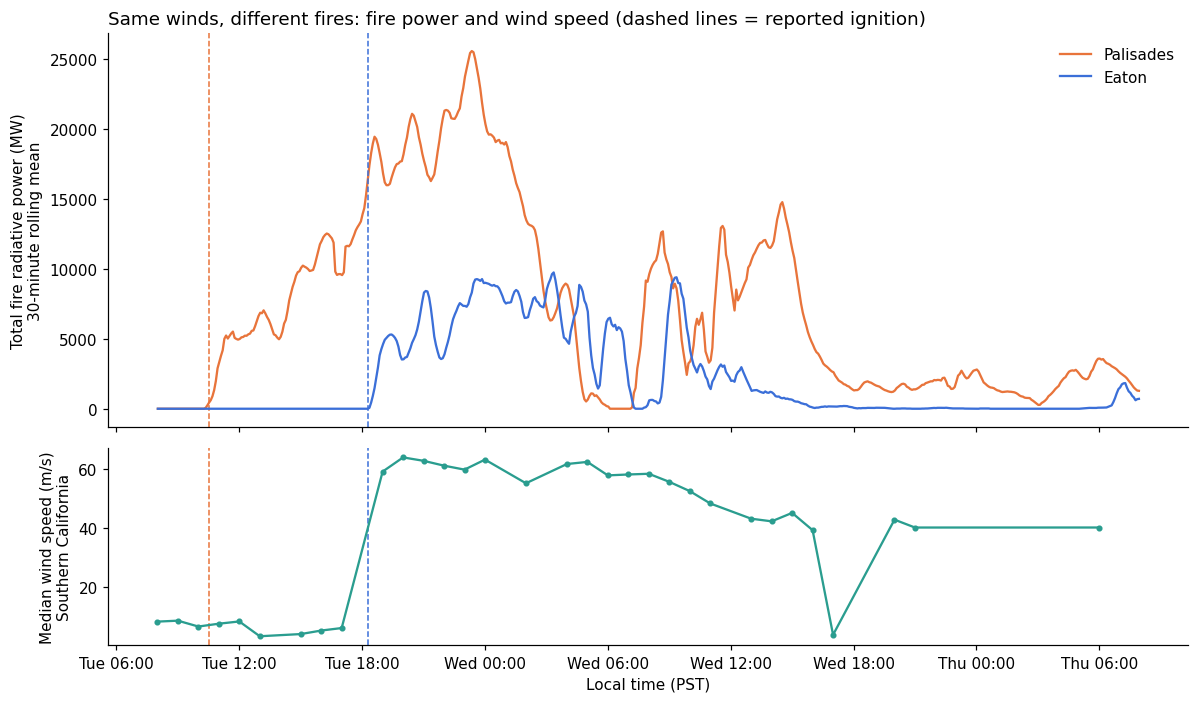

In [8]:
figure, (power_axis, wind_axis) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

for fire_name in FIRE_NAMES:
    fire_series = timeseries[timeseries["fire"] == fire_name]
    power_axis.plot(fire_series["time_local"], fire_series["frp_smooth"], color=FIRE_COLORS[fire_name], label=fire_name)
    ignition_local = FIRES[fire_name]["ignition"].tz_convert(LOCAL_TIMEZONE)
    power_axis.axvline(ignition_local, color=FIRE_COLORS[fire_name], linestyle="--", linewidth=1)
    wind_axis.axvline(ignition_local, color=FIRE_COLORS[fire_name], linestyle="--", linewidth=1)

power_axis.set_ylabel("Total fire radiative power (MW)\n30-minute rolling mean")
power_axis.legend(frameon=False)
power_axis.set_title("Same winds, different fires: fire power and wind speed (dashed lines = reported ignition)", loc="left")

if len(hourly_wind) > 0:
    wind_axis.plot(hourly_wind["hour_local"], hourly_wind["median_speed"], color=WIND_COLOR, marker="o", markersize=3)
    wind_axis.set_ylabel("Median wind speed (m/s)\nSouthern California")
else:
    wind_axis.text(0.5, 0.5, "No wind vectors found for this window", transform=wind_axis.transAxes, ha="center")

wind_axis.xaxis.set_major_formatter(mdates.DateFormatter("%a %H:%M", tz=LOCAL_TIMEZONE))
wind_axis.set_xlabel("Local time (PST)")
plt.tight_layout()
plt.savefig("fig1_power_and_wind.png", bbox_inches="tight")
plt.show()

## Fig 2: Where each fire spread, with the average wind direction

Each dot is a fire pixel colored by hours since that fire's ignition, so lighter dots burned first. Larger dots released more power. The star marks the reported ignition point, and the teal arrow shows the average direction the wind was blowing toward during that fire's first 12 hours.

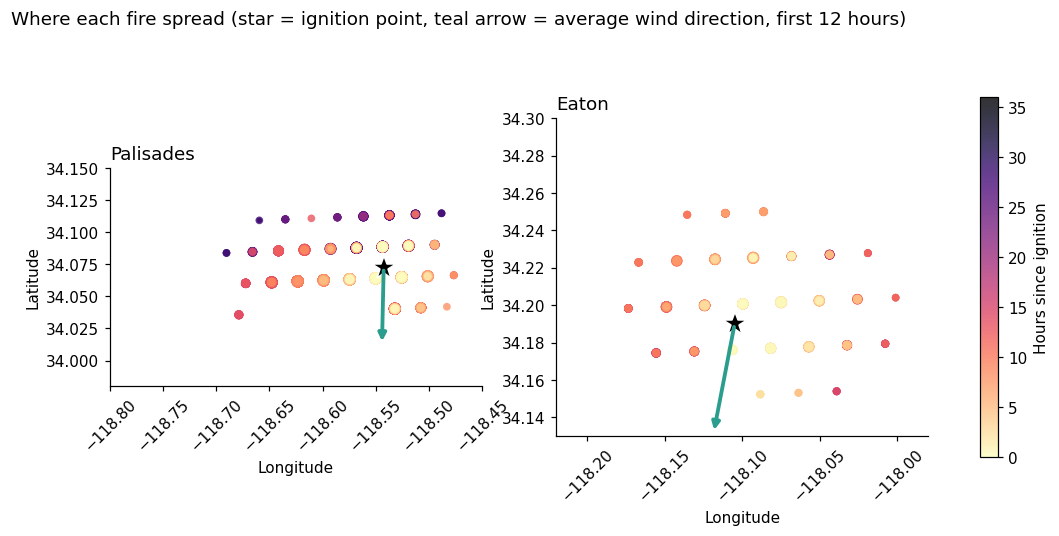

In [9]:
def average_wind_vector(start_time, hours):
    if len(winds) == 0:
        return None
    in_window = (winds["time"] >= start_time) & (winds["time"] < start_time + pd.Timedelta(hours=hours))
    window_winds = winds[in_window]
    if len(window_winds) == 0:
        return None
    return {"east": window_winds["wind_east"].mean(), "north": window_winds["wind_north"].mean()}


figure, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, fire_name in zip(axes, FIRE_NAMES):
    fire_points = detections[detections["fire"] == fire_name].sort_values("hours_since_ignition", ascending=False)
    scatter = axis.scatter(
        fire_points["lon"],
        fire_points["lat"],
        c=fire_points["hours_since_ignition"],
        cmap="magma_r",
        s=12 + fire_points["frp"].fillna(0) ** 0.5,
        vmin=0,
        vmax=36,
        edgecolor="none",
        alpha=0.8,
    )
    origin_longitude = FIRES[fire_name]["lon"]
    origin_latitude = FIRES[fire_name]["lat"]
    axis.plot(origin_longitude, origin_latitude, marker="*", markersize=16, color="black", markeredgecolor="white")

    wind_vector = average_wind_vector(FIRES[fire_name]["ignition"], 12)
    if wind_vector is not None:
        vector_length = np.sqrt(wind_vector["east"] ** 2 + wind_vector["north"] ** 2)
        arrow_end = (origin_longitude + 0.06 * wind_vector["east"] / vector_length, origin_latitude + 0.06 * wind_vector["north"] / vector_length)
        axis.annotate("", xy=arrow_end, xytext=(origin_longitude, origin_latitude), arrowprops={"arrowstyle": "-|>", "color": WIND_COLOR, "lw": 2.5})

    box = FIRES[fire_name]["box"]
    axis.set_xlim(box["west"], box["east"])
    axis.set_ylim(box["south"], box["north"])
    axis.set_aspect(1 / np.cos(np.radians(34)))
    axis.tick_params(axis="x", labelrotation=45)
    axis.set_title(fire_name, loc="left")
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")

figure.colorbar(scatter, ax=axes, label="Hours since ignition", shrink=0.85)
figure.suptitle("Where each fire spread (star = ignition point, teal arrow = average wind direction, first 12 hours)", x=0.05, ha="left")
plt.savefig("fig2_spread_maps_with_wind.png", bbox_inches="tight")
plt.show()

## Fig 3: The two fires on the same clock

Both fires are aligned to hours since their own ignition. The left panel counts distinct 2 km pixels each fire had reached (its growing footprint). The right panel shows how far from the ignition point the fire had reached (95th percentile distance, as a running maximum).

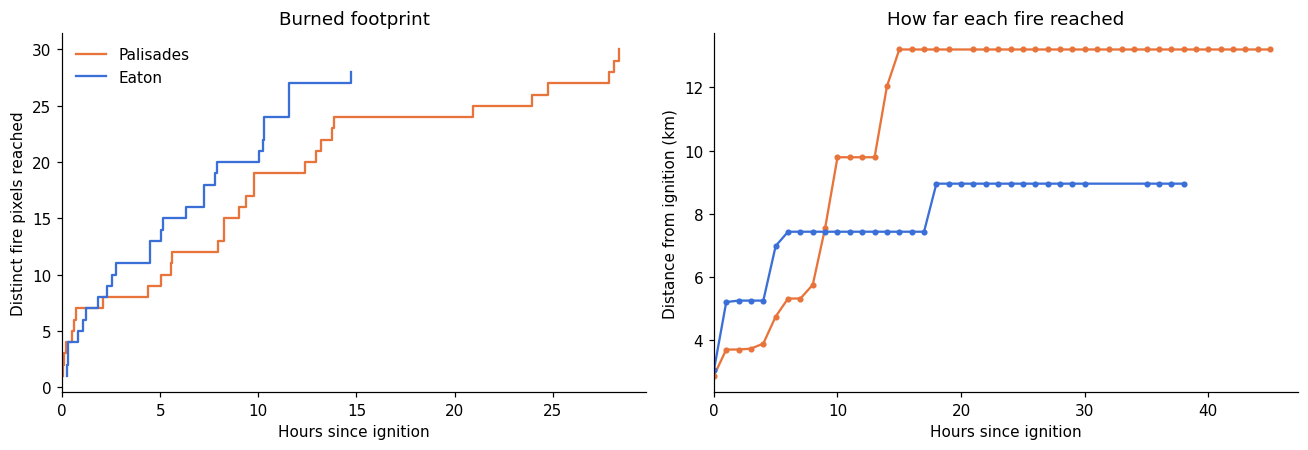

In [10]:
named = detections[detections["fire"].isin(FIRE_NAMES)].copy()
named["origin_lat"] = named["fire"].map(ORIGIN_LATITUDES)
named["origin_lon"] = named["fire"].map(ORIGIN_LONGITUDES)
named["distance_km"] = distance_km(named["origin_lat"], named["origin_lon"], named["lat"], named["lon"])
north_offset = named["lat"] - named["origin_lat"]
east_offset = (named["lon"] - named["origin_lon"]) * np.cos(np.radians(named["lat"]))
named["bearing_deg"] = (np.degrees(np.arctan2(east_offset, north_offset)) + 360) % 360

figure, (footprint_axis, reach_axis) = plt.subplots(1, 2, figsize=(12, 4.2))
for fire_name in FIRE_NAMES:
    fire_points = named[named["fire"] == fire_name].sort_values("time")
    first_time_burned = fire_points.drop_duplicates(["pixel_y", "pixel_x"])
    footprint_axis.step(first_time_burned["hours_since_ignition"], np.arange(1, len(first_time_burned) + 1), where="post", color=FIRE_COLORS[fire_name], label=fire_name)
    reach = fire_points.groupby(fire_points["hours_since_ignition"].round())["distance_km"].quantile(0.95).cummax()
    reach_axis.plot(reach.index, reach.values, color=FIRE_COLORS[fire_name], marker="o", markersize=3)

footprint_axis.set(xlabel="Hours since ignition", ylabel="Distinct fire pixels reached", title="Burned footprint")
reach_axis.set(xlabel="Hours since ignition", ylabel="Distance from ignition (km)", title="How far each fire reached")
footprint_axis.legend(frameon=False)
footprint_axis.set_xlim(0, None)
reach_axis.set_xlim(0, None)
plt.tight_layout()
plt.savefig("fig3_aligned_growth.png", bbox_inches="tight")
plt.show()

## Fig 4: Did each fire spread the way the wind blew?

Bars show the share of each fire's radiative power by direction from its ignition point (pixels within 1.5 km of the origin are skipped). The teal outline shows the share of wind vectors blowing **toward** each direction during that fire's first 24 hours. If a fire spread with the wind, the bars and the outline point the same way.

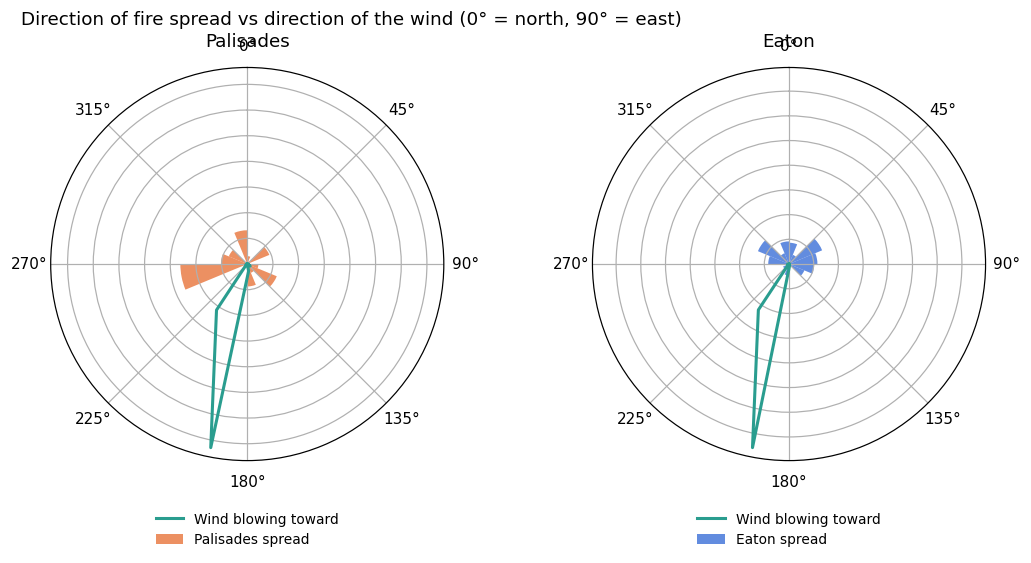

In [11]:
direction_bins = np.linspace(0, 360, 17)
bin_centers = np.radians(direction_bins[:-1] + 11.25)

figure, axes = plt.subplots(1, 2, figsize=(10, 5), subplot_kw={"projection": "polar"})
for axis, fire_name in zip(axes, FIRE_NAMES):
    away_from_origin = named[(named["fire"] == fire_name) & (named["distance_km"] > 1.5)]
    fire_counts, bin_edges = np.histogram(away_from_origin["bearing_deg"], bins=direction_bins, weights=away_from_origin["frp"].fillna(0))
    fire_share = fire_counts / fire_counts.sum()
    axis.bar(bin_centers, fire_share, width=np.radians(22.5), color=FIRE_COLORS[fire_name], alpha=0.8, label=f"{fire_name} spread")

    if len(winds) > 0:
        ignition = FIRES[fire_name]["ignition"]
        in_window = (winds["time"] >= ignition) & (winds["time"] < ignition + pd.Timedelta(hours=24))
        window_winds = winds[in_window]
        if len(window_winds) > 0:
            wind_counts, bin_edges = np.histogram(window_winds["direction_to_deg"], bins=direction_bins)
            wind_share = wind_counts / wind_counts.sum()
            closed_angles = np.append(bin_centers, bin_centers[0])
            closed_share = np.append(wind_share, wind_share[0])
            axis.plot(closed_angles, closed_share, color=WIND_COLOR, linewidth=2, label="Wind blowing toward")

    axis.set_theta_zero_location("N")
    axis.set_theta_direction(-1)
    axis.set_yticklabels([])
    axis.set_title(fire_name, pad=14)
    axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=9)

figure.suptitle("Direction of fire spread vs direction of the wind (0° = north, 90° = east)", x=0.05, ha="left")
plt.tight_layout()
plt.savefig("fig4_spread_vs_wind_direction.png", bbox_inches="tight")
plt.show()

## Fig 5: One moment, one wind field, two fires

A band 7 (3.9 µm) heat image at 3:00 AM PST on January 8, when both fires were burning. Bright pixels are hot. Teal arrows are satellite-derived winds within 90 minutes of this image, pointing in the direction the wind was blowing.

0 wind vectors drawn


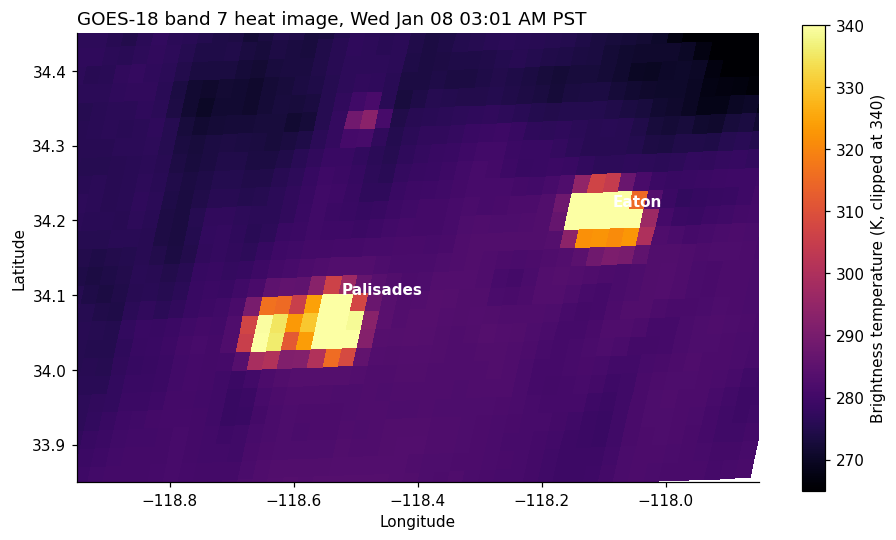

In [12]:
SNAPSHOT_TIME = pd.Timestamp("2025-01-08 11:00", tz="UTC")
band7_files = list_files("ABI-L2-CMIPC", SNAPSHOT_TIME, SNAPSHOT_TIME + pd.Timedelta(minutes=10), "C07_")
BAND7_ROWS, BAND7_COLUMNS, BAND7_LATITUDE, BAND7_LONGITUDE = find_region_window(band7_files["path"][0], LA_REGION)
with fs.open(band7_files["path"][0]) as remote_file:
    band7_scan = xr.open_dataset(remote_file, engine="h5netcdf")
    brightness_temperature = band7_scan["CMI"].isel(y=BAND7_ROWS, x=BAND7_COLUMNS).values

figure, axis = plt.subplots(figsize=(10, 5.5))
heat_map = axis.pcolormesh(BAND7_LONGITUDE, BAND7_LATITUDE, brightness_temperature, cmap="inferno", vmin=265, vmax=340, shading="auto")
for fire_name in FIRE_NAMES:
    axis.annotate(fire_name, (FIRES[fire_name]["lon"], FIRES[fire_name]["lat"]), xytext=(8, 14), textcoords="offset points", color="white", weight="bold")

if len(winds) > 0:
    near_snapshot = (winds["time"] >= SNAPSHOT_TIME - pd.Timedelta(minutes=90)) & (winds["time"] <= SNAPSHOT_TIME + pd.Timedelta(minutes=90))
    in_view = (winds["lon"] >= LA_REGION["west"]) & (winds["lon"] <= LA_REGION["east"]) & (winds["lat"] >= LA_REGION["south"]) & (winds["lat"] <= LA_REGION["north"])
    snapshot_winds = winds[near_snapshot & in_view]
    print(len(snapshot_winds), "wind vectors drawn")
    if len(snapshot_winds) > 0:
        axis.quiver(snapshot_winds["lon"], snapshot_winds["lat"], snapshot_winds["wind_east"], snapshot_winds["wind_north"], color=WIND_COLOR, scale=400, width=0.004)

axis.set_xlim(LA_REGION["west"], LA_REGION["east"])
axis.set_ylim(LA_REGION["south"], LA_REGION["north"])
axis.set_aspect(1 / np.cos(np.radians(34)))
axis.set_xlabel("Longitude")
axis.set_ylabel("Latitude")
snapshot_local = band7_files["time"][0].tz_convert(LOCAL_TIMEZONE)
axis.set_title(f"GOES-18 band 7 heat image, {snapshot_local.strftime('%a %b %d %I:%M %p')} PST", loc="left")
figure.colorbar(heat_map, label="Brightness temperature (K, clipped at 340)")
plt.savefig("fig5_heat_and_wind_snapshot.png", bbox_inches="tight")
plt.show()

## Fig 6: Did each fire burn harder when the wind was stronger?

Each dot is one hour after that fire's ignition: its average radiative power against the median wind speed that hour. If both fires were wind-driven in the same way, both clouds of dots would rise to the right.

Palisades correlation between hourly wind speed and fire power: 0.33 over 30 hours
Eaton correlation between hourly wind speed and fire power: 0.65 over 23 hours


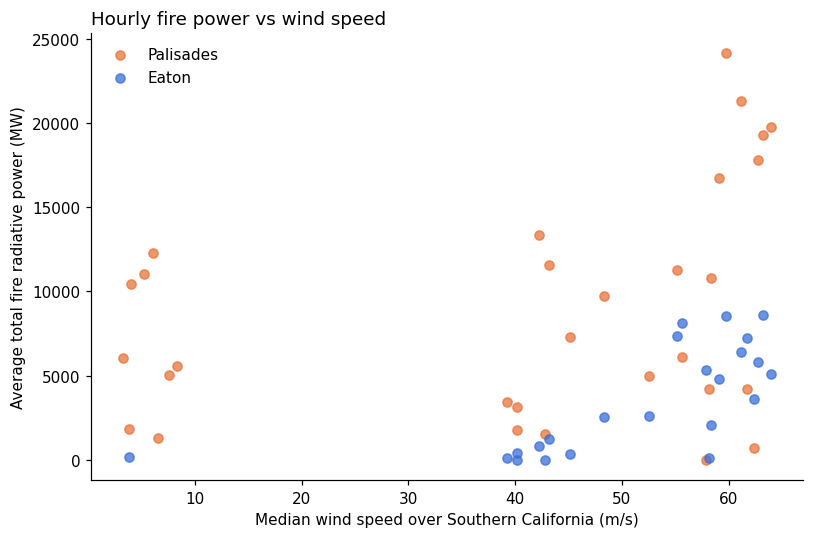

In [13]:
figure, axis = plt.subplots(figsize=(7.5, 5))
if len(hourly_wind) > 0:
    for fire_name in FIRE_NAMES:
        fire_series = timeseries[(timeseries["fire"] == fire_name) & (timeseries["time"] >= FIRES[fire_name]["ignition"])]
        hourly_power = fire_series.groupby("hour")["frp_total"].mean().reset_index()
        power_and_wind = hourly_power.merge(hourly_wind, on="hour")
        axis.scatter(power_and_wind["median_speed"], power_and_wind["frp_total"], color=FIRE_COLORS[fire_name], alpha=0.75, label=fire_name)
        if len(power_and_wind) >= 3:
            correlation = np.corrcoef(power_and_wind["median_speed"].astype(float), power_and_wind["frp_total"].astype(float))[0, 1]
            print(fire_name, "correlation between hourly wind speed and fire power:", round(correlation, 2), "over", len(power_and_wind), "hours")
    axis.legend(frameon=False)
else:
    axis.text(0.5, 0.5, "No wind vectors found for this window", transform=axis.transAxes, ha="center")
axis.set_xlabel("Median wind speed over Southern California (m/s)")
axis.set_ylabel("Average total fire radiative power (MW)")
axis.set_title("Hourly fire power vs wind speed", loc="left")
plt.tight_layout()
plt.savefig("fig6_power_vs_wind.png", bbox_inches="tight")
plt.show()

## Numbers for the narration

In [14]:
for fire_name in FIRE_NAMES:
    fire_series = timeseries[timeseries["fire"] == fire_name]
    fire_points = named[named["fire"] == fire_name]
    peak_row = fire_series.loc[fire_series["frp_smooth"].idxmax()]
    first_detection = fire_points["time"].min()
    minutes_after_ignition = round((first_detection - FIRES[fire_name]["ignition"]).total_seconds() / 60)
    first_time_burned = fire_points.sort_values("time").drop_duplicates(["pixel_y", "pixel_x"])
    away_from_origin = fire_points[fire_points["distance_km"] > 1.5]
    spread_direction = mean_direction(away_from_origin["bearing_deg"], away_from_origin["frp"].fillna(0))
    peak_hours = round((peak_row["time"] - FIRES[fire_name]["ignition"]).total_seconds() / 3600, 1)

    print(fire_name)
    print(f"  first GOES detection: {first_detection.tz_convert(LOCAL_TIMEZONE).strftime('%a %I:%M %p')} PST ({minutes_after_ignition} min after reported ignition)")
    print(f"  peak fire power: {round(peak_row['frp_smooth'])} MW at {peak_row['time_local'].strftime('%a %I:%M %p')} PST ({peak_hours} h after ignition)")
    print(f"  distinct pixels reached after 6 h: {(first_time_burned['hours_since_ignition'] <= 6).sum()}, after 12 h: {(first_time_burned['hours_since_ignition'] <= 12).sum()}")
    print(f"  power-weighted spread direction: {round(spread_direction)} degrees ({compass_name(spread_direction)})")

    if len(winds) > 0:
        ignition = FIRES[fire_name]["ignition"]
        first_day_winds = winds[(winds["time"] >= ignition) & (winds["time"] < ignition + pd.Timedelta(hours=24))]
        if len(first_day_winds) > 0:
            wind_toward = mean_direction(first_day_winds["direction_to_deg"].astype(float), first_day_winds["speed_ms"].astype(float))
            print(f"  average wind blowing toward: {round(wind_toward)} degrees ({compass_name(wind_toward)}), median speed {round(first_day_winds['speed_ms'].median(), 1)} m/s")

if len(hourly_wind) > 0:
    windiest_hour = hourly_wind.loc[hourly_wind["median_speed"].astype(float).idxmax()]
    print(f"Windiest hour in the window: {windiest_hour['hour_local'].strftime('%a %I %p')} PST, median {round(float(windiest_hour['median_speed']), 1)} m/s")

Palisades
  first GOES detection: Tue 10:31 AM PST (1 min after reported ignition)
  peak fire power: 25532 MW at Tue 11:21 PM PST (12.9 h after ignition)
  distinct pixels reached after 6 h: 12, after 12 h: 19
  power-weighted spread direction: 293 degrees (NW)
  average wind blowing toward: 198 degrees (S), median speed 57.8 m/s
Eaton
  first GOES detection: Tue 06:31 PM PST (13 min after reported ignition)
  peak fire power: 9729 MW at Wed 03:21 AM PST (9.1 h after ignition)
  distinct pixels reached after 6 h: 15, after 12 h: 27
  power-weighted spread direction: 28 degrees (NE)
  average wind blowing toward: 199 degrees (S), median speed 53.9 m/s
Windiest hour in the window: Tue 08 PM PST, median 63.9 m/s


## Export data for the D3 page

Writes `site_data.zip` with the detections, per-scan totals, wind vectors, a small metadata file, and all six figures.

In [15]:
os.makedirs("site_data", exist_ok=True)

detections_out = detections[["time", "fire", "lat", "lon", "frp", "temp", "area", "pixel_y", "pixel_x", "hours_since_ignition"]].copy()
detections_out["time"] = detections_out["time"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
detections_out.round({"lat": 4, "lon": 4, "frp": 1, "temp": 0, "area": 3, "hours_since_ignition": 3}).to_csv("site_data/detections.csv", index=False)

timeseries_out = timeseries[["time", "fire", "frp_total", "pixel_count", "frp_smooth"]].copy()
timeseries_out["time"] = timeseries_out["time"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
timeseries_out.round({"frp_total": 1, "frp_smooth": 1}).to_csv("site_data/timeseries.csv", index=False)

winds_out = winds[["time", "lat", "lon", "speed_ms", "direction_from_deg", "pressure_hpa", "source"]].copy()
winds_out["time"] = winds_out["time"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
winds_out.to_csv("site_data/winds.csv", index=False)

fire_metadata = {}
for fire_name in FIRE_NAMES:
    fire_metadata[fire_name] = {
        "ignition": FIRES[fire_name]["ignition"].strftime("%Y-%m-%dT%H:%M:%SZ"),
        "lat": FIRES[fire_name]["lat"],
        "lon": FIRES[fire_name]["lon"],
        "box": FIRES[fire_name]["box"],
    }
metadata = {
    "satellite": "GOES-18 (GOES-West)",
    "products": ["ABI-L2-FDCC", "ABI-L2-DMWC", "ABI-L2-DMWVC", "ABI-L2-CMIPC"],
    "start": START.strftime("%Y-%m-%dT%H:%M:%SZ"),
    "end": END.strftime("%Y-%m-%dT%H:%M:%SZ"),
    "fire_codes": FIRE_CODES,
    "fires": fire_metadata,
}
with open("site_data/meta.json", "w") as metadata_file:
    json.dump(metadata, metadata_file, indent=1)

with zipfile.ZipFile("site_data.zip", "w") as archive:
    for file_name in os.listdir("site_data"):
        archive.write(f"site_data/{file_name}", f"data/{file_name}")
    for file_name in sorted(os.listdir(".")):
        if file_name.startswith("fig") and file_name.endswith(".png"):
            archive.write(file_name, f"figures/{file_name}")

print("wrote site_data.zip:", os.path.getsize("site_data.zip") // 1024, "KB")
try:
    from google.colab import files
    files.download("site_data.zip")
except ImportError:
    pass

wrote site_data.zip: 1193 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>